In [12]:
import pandas as pd
books= pd.read_csv("../data/raw/books.csv")
print(f"Dataset size: {books.shape[0]:,} books × {books.shape[1]} columns")
books.head()

Dataset size: 17,976 books × 15 columns


,book_uid,title,series,author,first_published_year,publisher,isbn13,language_code,genres,goodreads_avg_rating,goodreads_ratings_count,goodreads_text_reviews_count,source,n_ratings,mean_rating_5
0,1,The Hunger Games,"The Hunger Games, #1",Suzanne Collins,2008.0,NaN,9.780439e+12,eng,young-adult|dystopian|science-fiction|fiction,4.34,4780653.0,155254.0,goodbooks,22806,4.280
1,2,Harry Potter and the Sorcerer's Stone,"Harry Potter, #1","J.K. Rowling, Mary GrandPré",1997.0,NaN,9.780440e+12,eng,fantasy|young-adult|fiction|childrens,4.44,4602479.0,75867.0,both,22237,4.355
2,3,Twilight,"Twilight, #1",Stephenie Meyer,2005.0,NaN,9.780316e+12,eng,young-adult|paranormal|fantasy|fiction,3.57,3866839.0,95009.0,goodbooks,16931,3.214
3,4,To Kill a Mockingbird,NaN,Harper Lee,1960.0,NaN,9.780061e+12,eng,classics|historical-fiction|young-adult|litera...,4.25,3198671.0,72586.0,both,19292,4.332
4,5,The Great Gatsby,NaN,F. Scott Fitzgerald,1925.0,NaN,9.780743e+12,eng,classics|fiction|literature|historical-fiction,3.89,2683664.0,51992.0,both,16725,3.774


In [13]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 17976 entries, 0 to 17975
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   book_uid                      17976 non-null  int64  
 1   title                         17976 non-null  str    
 2   series                        6416 non-null   str    
 3   author                        17976 non-null  str    
 4   first_published_year          17856 non-null  float64
 5   publisher                     7976 non-null   str    
 6   isbn13                        17401 non-null  float64
 7   language_code                 8916 non-null   str    
 8   genres                        9987 non-null   str    
 9   goodreads_avg_rating          10000 non-null  float64
 10  goodreads_ratings_count       10000 non-null  float64
 11  goodreads_text_reviews_count  10000 non-null  float64
 12  source                        17976 non-null  str    
 13  n_ratings   

In [14]:
missing_data = pd.DataFrame({
    "missing_count": books.isna().sum(),
    "missing_percentage": (books.isna().mean() * 100).round(2)
})

missing_data = missing_data.sort_values(
    by="missing_percentage",
    ascending=False
)

missing_data

,missing_count,missing_percentage
series,11560,64.31
publisher,10000,55.63
language_code,9060,50.40
genres,7989,44.44
goodreads_avg_rating,7976,44.37
goodreads_ratings_count,7976,44.37
goodreads_text_reviews_count,7976,44.37
isbn13,575,3.20
first_published_year,120,0.67
book_uid,0,0.00


In [15]:
source_analysis = books.groupby("source").agg(
    book_count=("book_uid", "count"),
    missing_genres=("genres", lambda x: x.isna().sum()),
    missing_goodreads=("goodreads_avg_rating", lambda x: x.isna().sum()),
    missing_language=("language_code", lambda x: x.isna().sum()),
    missing_publisher=("publisher", lambda x: x.isna().sum())
)

source_analysis

,book_count,missing_genres,missing_goodreads,missing_language,missing_publisher
source,,,,,
bookcrossing,7976,7976,7976,7976,0
both,3916,1,0,500,3916
goodbooks,6084,12,0,584,6084


In [16]:
print("Total books:", len(books))

print("Unique book IDs:", books["book_uid"].nunique())

print("Duplicate book IDs:", books["book_uid"].duplicated().sum())

Total books: 17976
Unique book IDs: 17976
Duplicate book IDs: 0


In [17]:
print("Unique ISBNs:", books["isbn13"].nunique())

print("Duplicate ISBNs:", books["isbn13"].duplicated().sum())

print("Missing ISBNs:", books["isbn13"].isna().sum())

Unique ISBNs: 17401
Duplicate ISBNs: 574
Missing ISBNs: 575


In [18]:
print("Duplicate titles:", books["title"].duplicated().sum())

Duplicate titles: 626


In [19]:
duplicate_titles = books[
    books["title"].duplicated(keep=False)
].sort_values("title")

duplicate_titles[
    ["book_uid", "title", "author", "isbn13", "source"]
].head(30)

,book_uid,title,author,isbn13,source
348,349,'Salem's Lot,Stephen King,9.780450e+12,both
1291,1292,'Salem's Lot,"Stephen King, Jerry N. Uelsmann",9.780386e+12,goodbooks
15963,16662,101 Dalmatians,Walt Disney,9.780717e+12,bookcrossing
14920,15198,101 Dalmatians,Justine Korman,9.780307e+12,bookcrossing
10066,10067,A Case of Need,Michael Crichton,9.780451e+12,bookcrossing
6112,6113,A Case of Need,"Jeffery Hudson, Michael Crichton",9.780451e+12,both
2847,2848,A God in Ruins,Kate Atkinson,9.780316e+12,goodbooks
13498,13594,A God in Ruins,Leon Uris,9.780061e+12,bookcrossing
17485,21769,A Man Rides Through,Stephen R. Donaldson,9.780345e+12,bookcrossing
12398,12433,A Man Rides Through,Stephen Donaldson,9.780345e+12,bookcrossing


In [20]:
isbn_counts = books["isbn13"].value_counts()

print("Non-missing ISBN records:", books["isbn13"].notna().sum())
print("Distinct ISBNs:", books["isbn13"].nunique())
print("ISBNs appearing more than once:", (isbn_counts > 1).sum())
print("Rows belonging to repeated ISBNs:", isbn_counts[isbn_counts > 1].sum())
print("Extra duplicate ISBN rows:", books["isbn13"].duplicated().sum())

Non-missing ISBN records: 17401
Distinct ISBNs: 17401
ISBNs appearing more than once: 0
Rows belonging to repeated ISBNs: 0
Extra duplicate ISBN rows: 574


In [21]:
duplicate_titles = books[
    books["title"].duplicated(keep=False)
].copy()

title_author_counts = (
    duplicate_titles
    .groupby("title")["author"]
    .nunique()
    .sort_values(ascending=False)
)

print("Duplicate title groups:", len(title_author_counts))
print("Titles with multiple author entries:", (title_author_counts > 1).sum())
print("Titles with one author entry:", (title_author_counts == 1).sum())

Duplicate title groups: 531
Titles with multiple author entries: 529
Titles with one author entry: 2


In [22]:
duplicate_title_author = (
    books.groupby(["title", "author"])
    .size()
    .reset_index(name="record_count")
    .query("record_count > 1")
    .sort_values("record_count", ascending=False)
)

print("Repeated title-author combinations:", len(duplicate_title_author))
display(duplicate_title_author.head(20))


Repeated title-author combinations: 2


,title,author,record_count
523,A Song of Ice and Fire,George R.R. Martin,2
13188,The Firm,John Grisham,2


In [23]:
books[
    books.duplicated(subset=["title", "author"], keep=False)
][
    ["book_uid", "title", "author", "isbn13", "source"]
].sort_values(["title", "source"])


,book_uid,title,author,isbn13,source
2148,2149,A Song of Ice and Fire,George R.R. Martin,9.780346e+12,goodbooks
2526,2527,A Song of Ice and Fire,George R.R. Martin,9.781780e+12,goodbooks
122,123,The Firm,John Grisham,9.780582e+12,both
7867,7868,The Firm,John Grisham,9.780440e+12,both


In [24]:
ratings_sample = pd.read_csv("../data/raw/ratings_sample_100k.csv")

print("Shape:", ratings_sample.shape)
print(ratings_sample.columns.tolist())


Shape: (100000, 6)
['user_uid', 'book_uid', 'rating_raw', 'rating_5', 'sentiment', 'source']


In [25]:
print("Dataset shape:", ratings_sample.shape)

print("\nMissing values:")
print(ratings_sample.isna().sum())

print("\nUnique users:", ratings_sample["user_uid"].nunique())
print("Unique books:", ratings_sample["book_uid"].nunique())

print("\nRaw rating distribution:")
print(ratings_sample["rating_raw"].value_counts().sort_index())

print("\nNormalized rating distribution:")
print(ratings_sample["rating_5"].value_counts().sort_index())

print("\nSentiment distribution:")
print(ratings_sample["sentiment"].value_counts())

print("\nSource distribution:")
print(ratings_sample["source"].value_counts())

Dataset shape: (100000, 6)

Missing values:
user_uid      0
book_uid      0
rating_raw    0
rating_5      0
sentiment     0
source        0
dtype: int64

Unique users: 46184
Unique books: 10661

Raw rating distribution:
rating_raw
1      1968
2      5796
3     22632
4     34946
5     32377
6       200
7       441
8       652
9       497
10      491
Name: count, dtype: int64

Normalized rating distribution:
rating_5
1.00     1968
1.44       12
1.89       36
2.00     5784
2.33       56
2.78      248
3.00    22596
3.22      200
3.67      441
4.00    34890
4.11      652
4.56      497
5.00    32620
Name: count, dtype: int64

Sentiment distribution:
sentiment
 1    68659
 0    23541
-1     7800
Name: count, dtype: int64

Source distribution:
source
goodbooks       97355
bookcrossing     2645
Name: count, dtype: int64


In [26]:
print("RAW RATINGS BY SOURCE")
display(pd.crosstab(
    ratings_sample["source"],
    ratings_sample["rating_raw"]
))

print("\nNORMALIZED RATINGS BY SOURCE")
display(pd.crosstab(
    ratings_sample["source"],
    ratings_sample["rating_5"]
))

print("\nSENTIMENT BY SOURCE")
display(pd.crosstab(
    ratings_sample["source"],
    ratings_sample["sentiment"]
))

RAW RATINGS BY SOURCE


rating_raw,1,2,3,4,5,6,7,8,9,10
source,,,,,,,,,,
bookcrossing,12,12,36,56,248,200,441,652,497,491
goodbooks,1956,5784,22596,34890,32129,0,0,0,0,0



NORMALIZED RATINGS BY SOURCE


rating_5,1.00,1.44,1.89,2.00,2.33,2.78,3.00,3.22,3.67,4.00,4.11,4.56,5.00
source,,,,,,,,,,,,,
bookcrossing,12,12,36,0,56,248,0,200,441,0,652,497,491
goodbooks,1956,0,0,5784,0,0,22596,0,0,34890,0,0,32129



SENTIMENT BY SOURCE


sentiment,-1,0,1
source,,,
bookcrossing,60,945,1640
goodbooks,7740,22596,67019


In [27]:
ratings_sample["rating_5"].value_counts().sort_index()

rating_5
1.00     1968
1.44       12
1.89       36
2.00     5784
2.33       56
2.78      248
3.00    22596
3.22      200
3.67      441
4.00    34890
4.11      652
4.56      497
5.00    32620
Name: count, dtype: int64

In [28]:
ratings_sample["rating_5"].value_counts(normalize=True).sort_index() * 100

rating_5
1.00     1.968
1.44     0.012
1.89     0.036
2.00     5.784
2.33     0.056
2.78     0.248
3.00    22.596
3.22     0.200
3.67     0.441
4.00    34.890
4.11     0.652
4.56     0.497
5.00    32.620
Name: proportion, dtype: float64

In [29]:
pd.crosstab(
    ratings_sample["source"],
    ratings_sample["rating_5"],
    normalize="index"
) * 100

rating_5,1.00,1.44,1.89,2.00,2.33,2.78,3.00,3.22,3.67,4.00,4.11,4.56,5.00
source,,,,,,,,,,,,,
bookcrossing,0.453686,0.453686,1.361059,0.000000,2.117202,9.376181,0.000000,7.561437,16.672968,0.000000,24.650284,18.79017,18.563327
goodbooks,2.009142,0.000000,0.000000,5.941143,0.000000,0.000000,23.209902,0.000000,0.000000,35.837913,0.000000,0.00000,33.001900


In [30]:
book_rating_counts = ratings_sample.groupby("book_uid").size()

book_rating_counts.describe()

count    10661.000000
mean         9.379983
std         20.549413
min          1.000000
25%          2.000000
50%          4.000000
75%          8.000000
max        392.000000
dtype: float64

In [31]:
rating_frequency_groups = pd.cut(
    book_rating_counts,
    bins=[0, 1, 5, 10, 20, 50, 100, float("inf")],
    labels=["1", "2–5", "6–10", "11–20", "21–50", "51–100", "100+"]
)

rating_frequency_groups.value_counts().sort_index()

1         2055
2–5       4560
6–10      1966
11–20     1107
21–50      655
51–100     210
100+       108
Name: count, dtype: int64

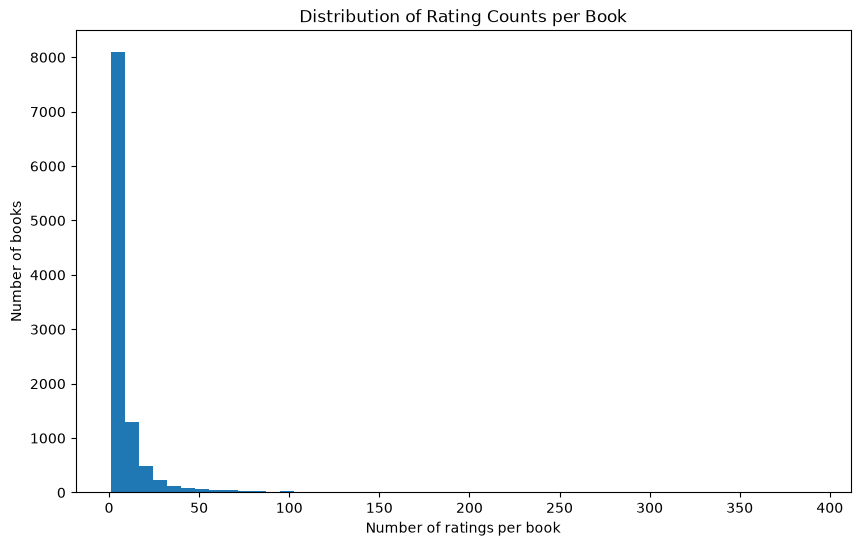

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(book_rating_counts, bins=50)

plt.xlabel("Number of ratings per book")
plt.ylabel("Number of books")
plt.title("Distribution of Rating Counts per Book")

plt.show()



In [33]:
top_10_books = book_rating_counts.sort_values(ascending=False).head(10)

top_10_books

book_uid
1     392
2     377
4     345
17    281
25    274
23    274
18    268
5     267
3     266
7     253
dtype: int64

In [35]:
top_10_books_df=(
    top_10_books.rename("rating_count")
    .reset_index()
    .merge(
        books[["book_uid", "title", "author"]],
        on="book_uid",
        how="left"
    )
    .sort_values("rating_count", ascending=False)
)
top_10_books_df

,book_uid,rating_count,title,author
0,1,392,The Hunger Games,Suzanne Collins
1,2,377,Harry Potter and the Sorcerer's Stone,"J.K. Rowling, Mary GrandPré"
2,4,345,To Kill a Mockingbird,Harper Lee
3,17,281,Catching Fire,Suzanne Collins
4,25,274,Harry Potter and the Deathly Hallows,"J.K. Rowling, Mary GrandPré"
5,23,274,Harry Potter and the Chamber of Secrets,"J.K. Rowling, Mary GrandPré"
6,18,268,Harry Potter and the Prisoner of Azkaban,"J.K. Rowling, Mary GrandPré, Rufus Beck"
7,5,267,The Great Gatsby,F. Scott Fitzgerald
8,3,266,Twilight,Stephenie Meyer
9,7,253,The Hobbit,J.R.R. Tolkien


In [36]:
top_10_percentage = (top_10_books.sum() / len(ratings_sample)) * 100

top_10_percentage

np.float64(2.997)

In [37]:
user_rating_counts = ratings_sample.groupby("user_uid").size()

user_rating_counts.describe()

count    46184.000000
mean         2.165252
std          1.249462
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         38.000000
dtype: float64

In [38]:
total_users = ratings_sample["user_uid"].nunique()
total_books = ratings_sample["book_uid"].nunique()
total_interactions = ratings_sample[["user_uid", "book_uid"]].drop_duplicates().shape[0]

total_possible_interactions = total_users * total_books

sparsity = 1 - (total_interactions / total_possible_interactions)

print("Users:", total_users)
print("Books:", total_books)
print("Actual interactions:", total_interactions)
print("Possible interactions:", total_possible_interactions)
print("Matrix sparsity:", sparsity * 100, "%")

Users: 46184
Books: 10661
Actual interactions: 100000
Possible interactions: 492367624
Matrix sparsity: 99.97968997246659 %
